# Student Performance ML Pipeline Using Decision Tree

This project builds a beginner-friendly machine learning pipeline that predicts a student's performance class from demographic, academic, and behavioral information. Predicting performance classes can help educators identify patterns in student records and support data-informed academic discussions.

**Objective:** train and evaluate a Decision Tree Classification model using the twelve requested input features. `StudentID` is an identifier and `GPA` is excluded because it is directly related to academic performance and could cause target leakage. The supplied GradeClass definition is `0 = A`, `1 = B`, `2 = C`, `3 = D`, and `4 = F`.

## 1. Import Required Libraries
The libraries below support data handling, visualization, preprocessing, model training, evaluation, and model saving.

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Dataset Loading
The CSV is loaded with Pandas. The original dataframe is kept unchanged so that the raw data remains available for reference.

In [2]:
DATA_PATH = 'Student_performance_data _.csv'
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f'Could not find {DATA_PATH!r} in the notebook folder.')

original_data = pd.read_csv(DATA_PATH)
processed_data = original_data.copy()

print('First five records:')
display(original_data.head())
print('Last five records:')
display(original_data.tail())
print('Dataset shape:', original_data.shape)
print('Column names:', original_data.columns.tolist())
print('Data types:')
display(original_data.dtypes.to_frame('dtype'))

First five records:


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


Last five records:


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
2387,3388,18,1,0,3,10.680555,2,0,4,1,0,0,0,3.455509,0.0
2388,3389,17,0,0,1,7.583217,4,1,4,0,1,0,0,3.279150,4.0
2389,3390,16,1,0,2,6.805500,20,0,2,0,0,0,1,1.142333,2.0
2390,3391,16,1,1,0,12.416653,17,0,2,0,1,1,0,1.803297,1.0
2391,3392,16,1,0,2,17.819907,13,0,2,0,0,0,1,2.140014,1.0


Dataset shape: (2392, 15)
Column names: ['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']
Data types:


,dtype
StudentID,int64
Age,int64
Gender,int64
Ethnicity,int64
ParentalEducation,int64
StudyTimeWeekly,float64
Absences,int64
Tutoring,int64
ParentalSupport,int64
Extracurricular,int64


## 3. Dataset Understanding
The dataset columns represent the following information:

### Student Information

- `StudentID`: unique identifier assigned to each student; not used for prediction. The supplied identifiers range from 1001 to 3392.
- `Age`: student age, ranging from 15 to 18 years.
- `Gender`: coded gender, where `0` represents Male and `1` represents Female.
- `Ethnicity`: coded ethnicity: `0` Caucasian, `1` African American, `2` Asian, and `3` Other.
- `ParentalEducation`: coded parental education: `0` None, `1` High School, `2` Some College, `3` Bachelor's, and `4` Higher.

### Study Habits and Support

- `StudyTimeWeekly`: weekly study time in hours, ranging from 0 to 20.
- `Absences`: number of absences during the school year, ranging from 0 to 30.
- `Tutoring`: tutoring status, where `0` means No and `1` means Yes.
- `ParentalSupport`: coded parental support: `0` None, `1` Low, `2` Moderate, `3` High, and `4` Very High.

### Extracurricular Activities

- `Extracurricular`, `Sports`, `Music`, and `Volunteering`: participation indicators, where `0` means No and `1` means Yes.

### Academic Performance

- `GPA`: grade point average on a scale from 2.0 to 4.0. It is excluded from model inputs because it is directly related to the target and could cause target leakage.
- `GradeClass`: target variable based on GPA: `0` = A (`GPA >= 3.5`), `1` = B (`3.0 <= GPA < 3.5`), `2` = C (`2.5 <= GPA < 3.0`), `3` = D (`2.0 <= GPA < 2.5`), and `4` = F (`GPA < 2.0`).

The supplied file stores these coded categorical values as integers. They are treated as categorical variables rather than continuous measurements.

In [3]:
print('Descriptive statistics:')
display(original_data.describe(include='all').T)

categorical_columns_in_data = [
    'Gender', 'Ethnicity', 'ParentalEducation', 'Tutoring', 'ParentalSupport',
    'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GradeClass'
]
for column in categorical_columns_in_data:
    print(f'Unique values in {column}:', sorted(original_data[column].dropna().unique().tolist()))

print('Observed GradeClass values:', sorted(original_data['GradeClass'].dropna().unique().tolist()))

Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
StudentID,2392.0,2196.500000,690.655244,1001.000000,1598.750000,2196.500000,2794.250000,3392.000000
Age,2392.0,16.468645,1.123798,15.000000,15.000000,16.000000,17.000000,18.000000
Gender,2392.0,0.510870,0.499986,0.000000,0.000000,1.000000,1.000000,1.000000
Ethnicity,2392.0,0.877508,1.028476,0.000000,0.000000,0.000000,2.000000,3.000000
ParentalEducation,2392.0,1.746237,1.000411,0.000000,1.000000,2.000000,2.000000,4.000000
StudyTimeWeekly,2392.0,9.771992,5.652774,0.001057,5.043079,9.705363,14.408410,19.978094
Absences,2392.0,14.541388,8.467417,0.000000,7.000000,15.000000,22.000000,29.000000
Tutoring,2392.0,0.301421,0.458971,0.000000,0.000000,0.000000,1.000000,1.000000
ParentalSupport,2392.0,2.122074,1.122813,0.000000,1.000000,2.000000,3.000000,4.000000
Extracurricular,2392.0,0.383361,0.486307,0.000000,0.000000,0.000000,1.000000,1.000000


Unique values in Gender: [0, 1]
Unique values in Ethnicity: [0, 1, 2, 3]
Unique values in ParentalEducation: [0, 1, 2, 3, 4]
Unique values in Tutoring: [0, 1]
Unique values in ParentalSupport: [0, 1, 2, 3, 4]
Unique values in Extracurricular: [0, 1]
Unique values in Sports: [0, 1]
Unique values in Music: [0, 1]
Unique values in Volunteering: [0, 1]
Unique values in GradeClass: [0.0, 1.0, 2.0, 3.0, 4.0]
Observed GradeClass values: [0.0, 1.0, 2.0, 3.0, 4.0]


## 4. Data Quality Checking
Missing values, duplicate rows, and basic range checks are reviewed before modeling. The target distribution is also displayed to show whether the classes are balanced.

In [4]:
print('Missing values by column:')
display(original_data.isna().sum().to_frame('missing_values'))
print('Duplicate rows:', int(original_data.duplicated().sum()))

range_checks = pd.DataFrame({
    'minimum': original_data.min(numeric_only=True),
    'maximum': original_data.max(numeric_only=True)
})
print('Numeric range checks:')
display(range_checks)

target_counts = original_data['GradeClass'].value_counts().sort_index()
print('GradeClass distribution:')
display(target_counts.to_frame('count'))

if original_data.isna().sum().sum() == 0 and original_data.duplicated().sum() == 0:
    print('No missing values or duplicate records were found. The pipeline still includes imputers for robustness.')
else:
    print('Potential data-quality issues were found and will be handled by preprocessing where appropriate.')

Missing values by column:


,missing_values
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


Duplicate rows: 0
Numeric range checks:


,minimum,maximum
StudentID,1001.000000,3392.000000
Age,15.000000,18.000000
Gender,0.000000,1.000000
Ethnicity,0.000000,3.000000
ParentalEducation,0.000000,4.000000
StudyTimeWeekly,0.001057,19.978094
Absences,0.000000,29.000000
Tutoring,0.000000,1.000000
ParentalSupport,0.000000,4.000000
Extracurricular,0.000000,1.000000


GradeClass distribution:


,count
GradeClass,
0.0,107
1.0,269
2.0,391
3.0,414
4.0,1211


No missing values or duplicate records were found. The pipeline still includes imputers for robustness.


## 5. Data Preprocessing
`processed_data` is a copy of the original data. `StudentID` is removed because it identifies a row rather than describing student behavior. `GPA` is excluded to reduce target leakage. The remaining columns are split into input features (`X`) and target (`y`). Numeric columns are median-imputed, while categorical columns are most-frequent-imputed and one-hot encoded. This lets the model use the coded categories without treating their numeric codes as ordered quantities.

In [5]:
input_features = [
    'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly',
    'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular',
    'Sports', 'Music', 'Volunteering'
]
target_column = 'GradeClass'

processed_data = processed_data.drop(columns=['StudentID'])
X = processed_data[input_features].copy()
y = processed_data[target_column].copy()

categorical_features = [
    'Gender', 'Ethnicity', 'ParentalEducation', 'Tutoring', 'ParentalSupport',
    'Extracurricular', 'Sports', 'Music', 'Volunteering'
]
numerical_features = ['Age', 'StudyTimeWeekly', 'Absences']

numeric_pipeline = Pipeline([('imputer', SimpleImputer(strategy='median'))])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numerical_features),
    ('categorical', categorical_pipeline, categorical_features)
])

print('Model input features:', input_features)
print('Target column:', target_column)
print('X shape:', X.shape, '| y shape:', y.shape)

Model input features: ['Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering']
Target column: GradeClass
X shape: (2392, 12) | y shape: (2392,)


## 6. Exploratory Data Analysis
The following plots describe the observed data. Visual patterns are treated as descriptive associations only; they do not prove that one variable causes another.

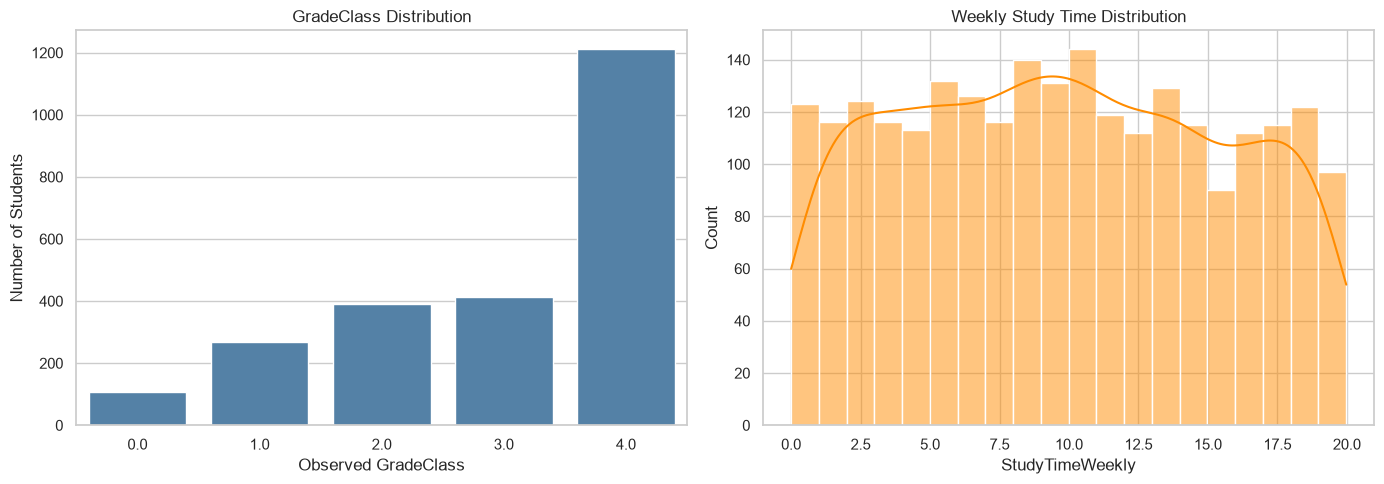

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=original_data, x='GradeClass', ax=axes[0], color='steelblue')
axes[0].set_title('GradeClass Distribution')
axes[0].set_xlabel('Observed GradeClass')
axes[0].set_ylabel('Number of Students')
sns.histplot(data=original_data, x='StudyTimeWeekly', bins=20, kde=True, ax=axes[1], color='darkorange')
axes[1].set_title('Weekly Study Time Distribution')
axes[1].set_xlabel('StudyTimeWeekly')
plt.tight_layout()
plt.show()

**Observation:** The class counts are uneven, with the displayed frequencies showing the observed distribution. Weekly study time is shown across its recorded range; the histogram describes the sample and does not by itself establish a relationship with `GradeClass`.

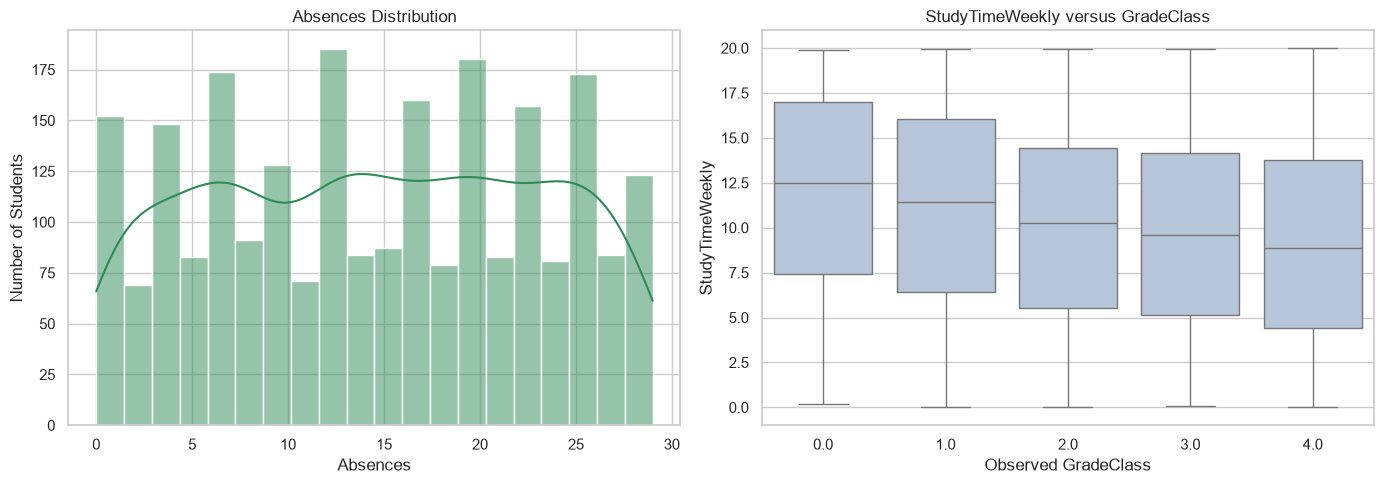

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=original_data, x='Absences', bins=20, kde=True, ax=axes[0], color='seagreen')
axes[0].set_title('Absences Distribution')
axes[0].set_xlabel('Absences')
axes[0].set_ylabel('Number of Students')
sns.boxplot(data=original_data, x='GradeClass', y='StudyTimeWeekly', ax=axes[1], color='lightsteelblue')
axes[1].set_title('StudyTimeWeekly versus GradeClass')
axes[1].set_xlabel('Observed GradeClass')
axes[1].set_ylabel('StudyTimeWeekly')
plt.tight_layout()
plt.show()

**Observation:** The absences histogram shows how absence counts are distributed in this dataset. The boxplots allow study-time distributions to be compared across observed classes; overlap between boxes or broad spreads should be interpreted as evidence that study time alone does not perfectly separate the classes.

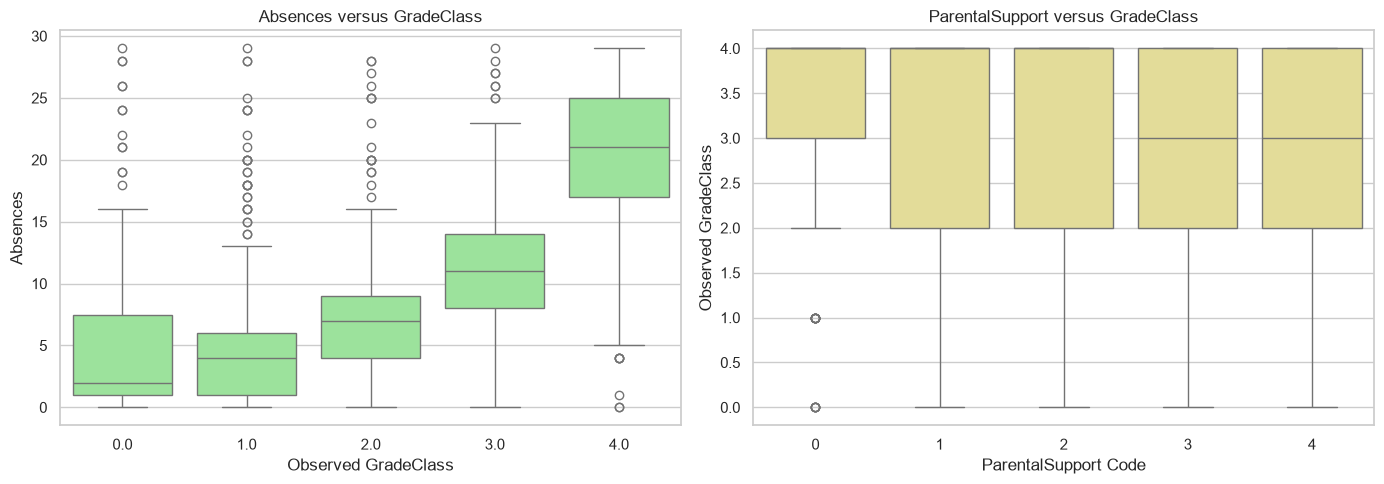

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=original_data, x='GradeClass', y='Absences', ax=axes[0], color='lightgreen')
axes[0].set_title('Absences versus GradeClass')
axes[0].set_xlabel('Observed GradeClass')
axes[0].set_ylabel('Absences')
sns.boxplot(data=original_data, x='ParentalSupport', y='GradeClass', ax=axes[1], color='khaki')
axes[1].set_title('ParentalSupport versus GradeClass')
axes[1].set_xlabel('ParentalSupport Code')
axes[1].set_ylabel('Observed GradeClass')
plt.tight_layout()
plt.show()

**Observation:** These plots compare absence and parental-support values across the observed target labels. Any differences in medians or spread are descriptive patterns in this sample and should not be presented as causal effects.

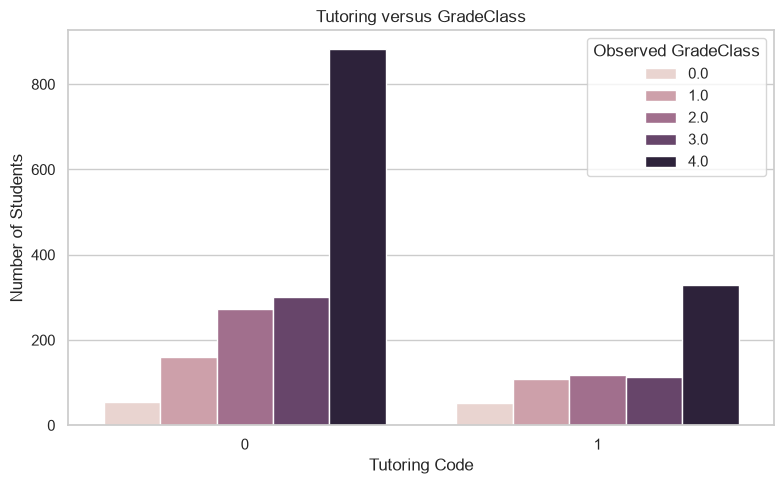

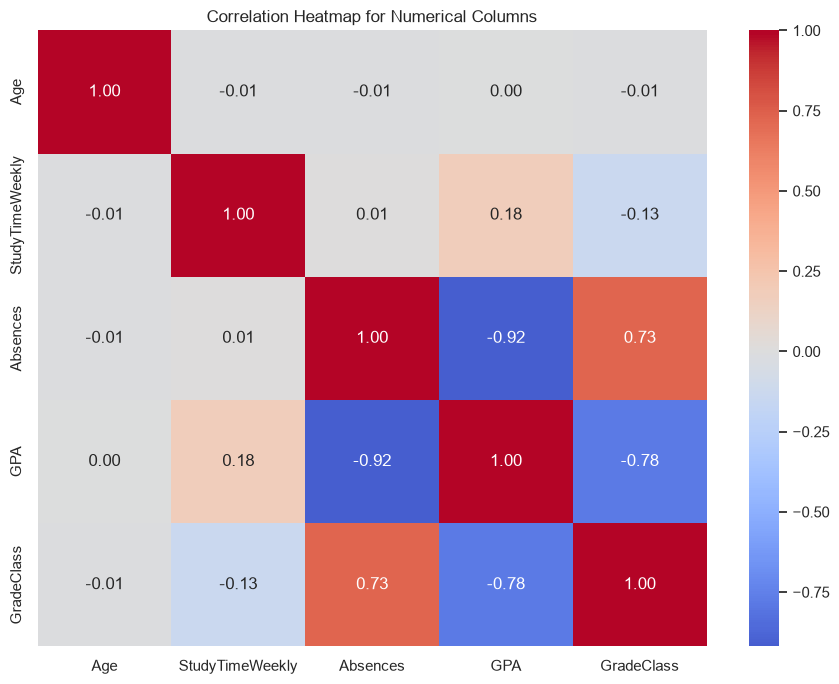

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.countplot(data=original_data, x='Tutoring', hue='GradeClass', ax=ax)
ax.set_title('Tutoring versus GradeClass')
ax.set_xlabel('Tutoring Code')
ax.set_ylabel('Number of Students')
ax.legend(title='Observed GradeClass')
plt.tight_layout()
plt.show()

numerical_columns = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA', 'GradeClass']
plt.figure(figsize=(9, 7))
sns.heatmap(original_data[numerical_columns].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap for Numerical Columns')
plt.tight_layout()
plt.show()

**Observation:** The tutoring count plot shows class frequencies within each tutoring code. The heatmap summarizes linear correlations among the listed numeric columns, including `GPA` for data understanding; `GPA` remains excluded from model inputs. Correlation is not proof of causation and does not capture every nonlinear relationship.

## 7. Decision Tree Algorithm Explanation
Supervised learning learns a relationship from examples that contain input features and a known target. Classification is supervised learning where the target is a category or class.

A Decision Tree repeatedly splits records using feature-based rules. The **root node** is the first split, a **decision node** is an internal rule, a **branch** is an outcome of a rule, and a **leaf node** contains the final predicted class.

Gini impurity measures how mixed the classes are in a node. Entropy measures uncertainty. Information gain compares parent uncertainty with the weighted uncertainty after a split. The classifier chooses useful splits during training, and a new student follows the learned branches until reaching a leaf.

$$Gini(S) = 1 - \sum_{i=1}^{n} p_i^2$$

$$Entropy(S) = -\sum_{i=1}^{n} p_i \log_2(p_i)$$

$$InformationGain(S,A)
=
Entropy(S)
-
\sum_{v \in Values(A)}
\frac{|S_v|}{|S|}
Entropy(S_v)$$

This project uses the Gini criterion and limits tree depth to help reduce overfitting.

## 8. Model Preparation and Training
A stratified split keeps approximately the same target-class proportions in the training and test sets. `random_state=42` makes the split and model reproducible.

The preprocessing object is fitted on the training data (`X_train`) to prevent data leakage and transforms both the training and test sets into **29 processed features** (3 numeric columns and 26 one-hot encoded category indicators). The Decision Tree model is then trained directly on this complete processed data (`X_train_processed`).

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Fit preprocessor on training data and transform train & test sets to complete processed data (29 features)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
transformed_feature_names = preprocessor.get_feature_names_out()

# Create DataFrames with feature names for inspectability
X_train_processed_df = pd.DataFrame(X_train_processed, columns=transformed_feature_names)
X_test_processed_df = pd.DataFrame(X_test_processed, columns=transformed_feature_names)

# Train Decision Tree classifier directly on the complete processed data (29 features)
decision_tree_model = DecisionTreeClassifier(
    criterion='gini', max_depth=5, random_state=RANDOM_STATE
)
decision_tree_model.fit(X_train_processed, y_train)

# Also retain an end-to-end pipeline for convenience
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', decision_tree_model)
])

print('Training rows:', len(X_train))
print('Testing rows:', len(X_test))
print('Number of raw input features:', X_train.shape[1])
print('Number of complete processed features:', X_train_processed.shape[1])
print('Model configuration: criterion=gini, max_depth=5, random_state=42')

Training rows: 1913
Testing rows: 479
Number of raw input features: 12
Number of complete processed features: 29
Model configuration: criterion=gini, max_depth=5, random_state=42


## 9. Model Evaluation
Accuracy is the proportion of all correct predictions. Precision measures how often predictions for a class are correct. Recall measures how many actual members of a class were found. The F1-score balances precision and recall. The classification report gives class-level metrics, while the confusion matrix shows actual classes against predicted classes.

,Metric,Value
0,Accuracy,0.691023
1,Precision (weighted),0.700649
2,Recall (weighted),0.691023
3,F1-score (weighted),0.688588


Classification report:
              precision    recall  f1-score   support

         0.0       0.60      0.14      0.23        21
         1.0       0.46      0.57      0.51        54
         2.0       0.51      0.49      0.50        78
         3.0       0.46      0.52      0.49        83
         4.0       0.91      0.89      0.90       243

    accuracy                           0.69       479
   macro avg       0.59      0.52      0.52       479
weighted avg       0.70      0.69      0.69       479



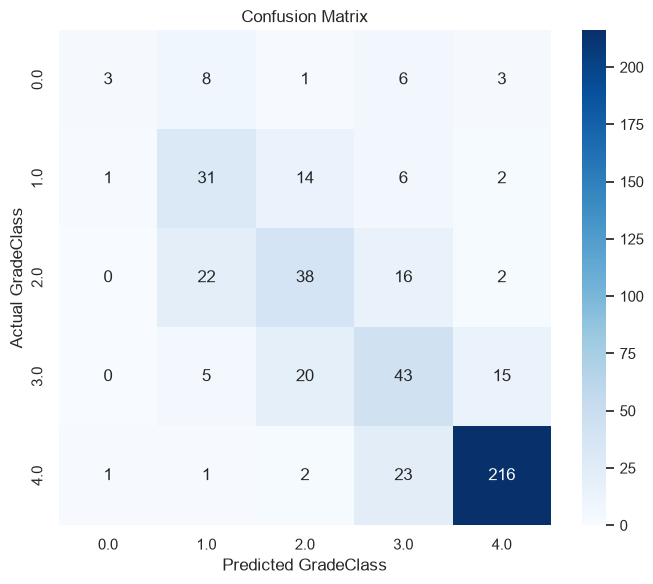

In [11]:
# Predict using the Decision Tree model on the complete processed test data (29 features)
predicted_classes = decision_tree_model.predict(X_test_processed)
observed_classes = sorted(y.unique().tolist())
metrics_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1-score (weighted)'],
    'Value': [
        accuracy_score(y_test, predicted_classes),
        precision_score(y_test, predicted_classes, average='weighted', zero_division=0),
        recall_score(y_test, predicted_classes, average='weighted', zero_division=0),
        f1_score(y_test, predicted_classes, average='weighted', zero_division=0)
    ]
})
display(metrics_summary)
print('Classification report:')
print(classification_report(y_test, predicted_classes, labels=observed_classes, zero_division=0))

confusion = confusion_matrix(y_test, predicted_classes, labels=observed_classes)
plt.figure(figsize=(7, 6))
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues',
            xticklabels=observed_classes, yticklabels=observed_classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted GradeClass')
plt.ylabel('Actual GradeClass')
plt.tight_layout()
plt.show()

The values above are calculated from the held-out test set at runtime. They are reported as evidence from this split and should not be interpreted as a guarantee of future performance.

## 10. Decision Tree Visualization
The fitted tree is displayed with readable transformed feature names. Each path from the root to a leaf represents a sequence of learned decisions. A depth limit keeps the diagram readable and helps control overfitting.

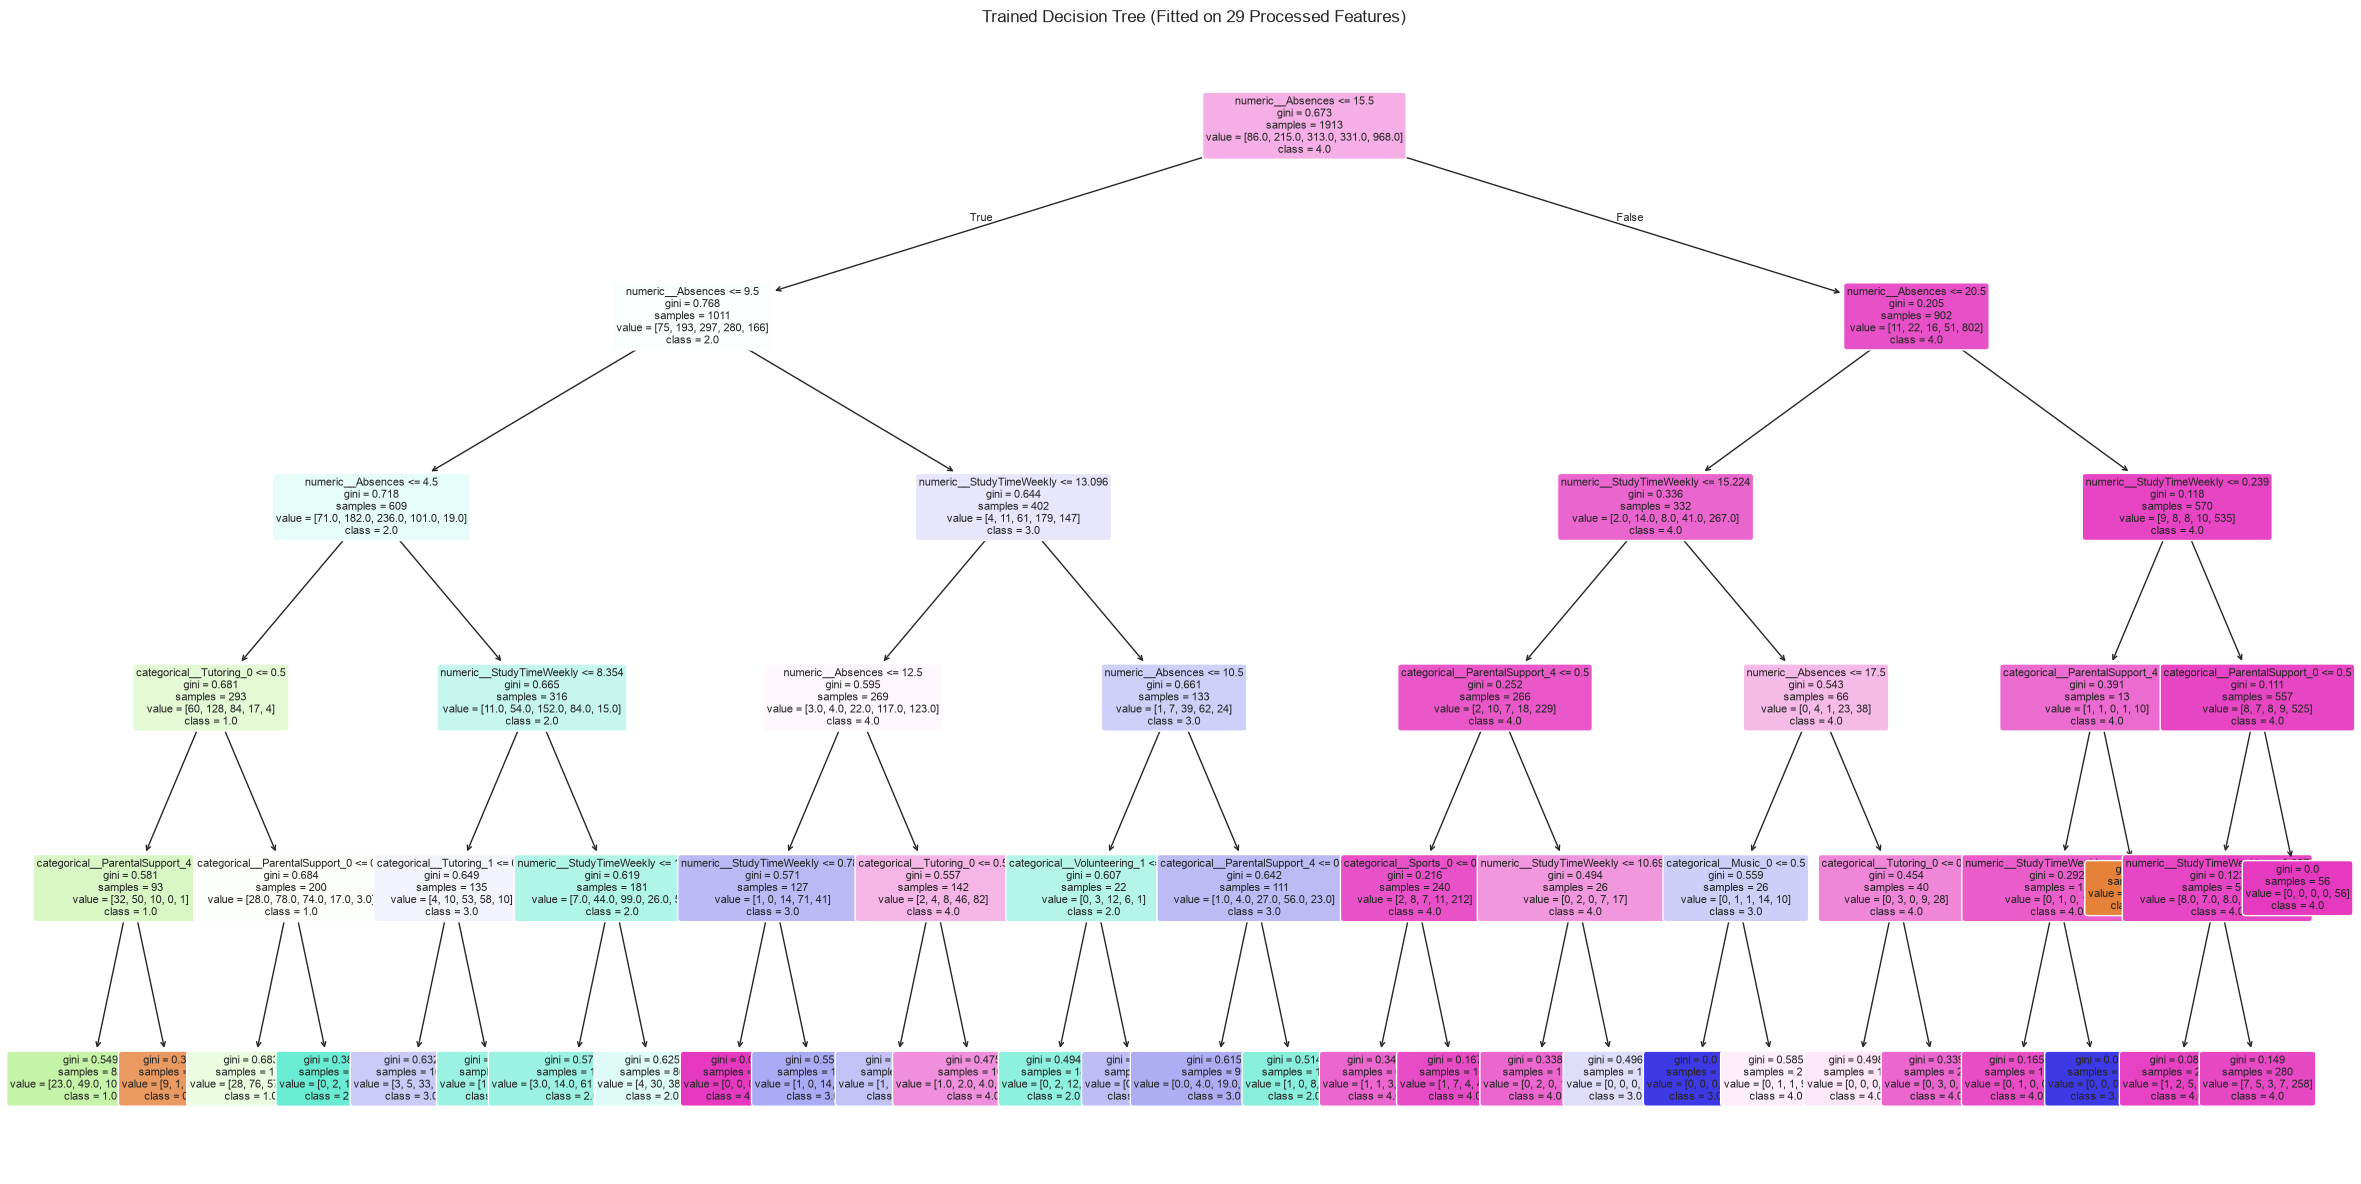

In [17]:
fitted_preprocessor = preprocessor
fitted_classifier = decision_tree_model
transformed_feature_names = fitted_preprocessor.get_feature_names_out()

plt.figure(figsize=(24, 12))
plot_tree(
    fitted_classifier,
    feature_names=transformed_feature_names,
    class_names=[str(value) for value in fitted_classifier.classes_],
    filled=True, rounded=True, fontsize=8
)
plt.title('Trained Decision Tree (Fitted on 29 Processed Features)')
plt.tight_layout()
plt.show()

## 11. Feature Importance
Feature importance indicates how much a transformed feature contributed to the splits of this trained tree. It is model-specific and should not be treated as a universal ranking or proof that a feature causes the target outcome. One-hot encoded category levels are shown separately.

,importance
numeric__Absences,0.831219
numeric__StudyTimeWeekly,0.081662
categorical__Tutoring_0,0.031071
categorical__ParentalSupport_4,0.025297
categorical__ParentalSupport_0,0.012794
categorical__Tutoring_1,0.008348
categorical__Music_0,0.004126
categorical__Volunteering_1,0.003616
categorical__Sports_0,0.001867
categorical__Ethnicity_0,0.000000


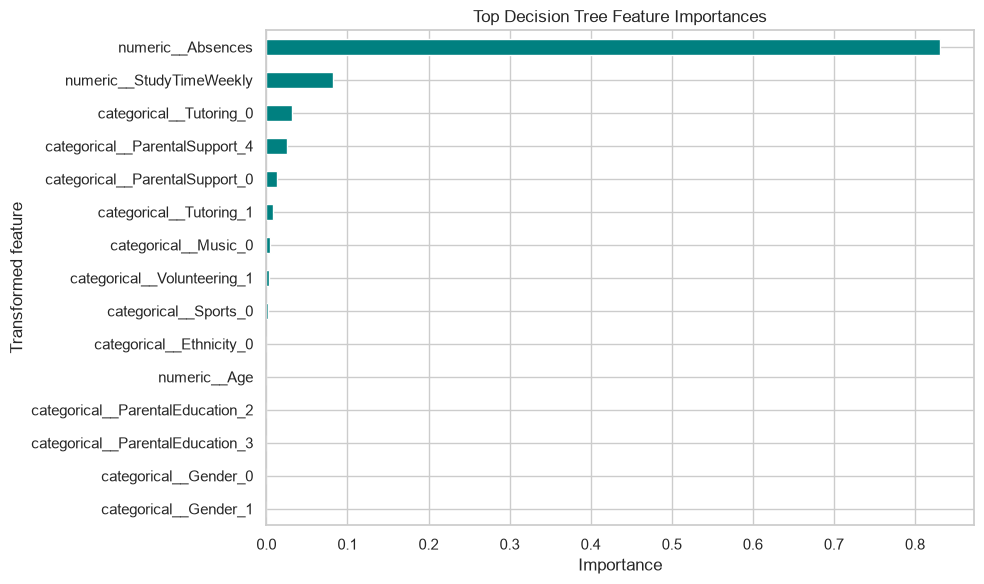

In [13]:
feature_importance = pd.Series(
    fitted_classifier.feature_importances_, index=transformed_feature_names
).sort_values(ascending=False)
display(feature_importance.to_frame('importance'))

plt.figure(figsize=(10, 6))
feature_importance.head(15).sort_values().plot(kind='barh', color='teal')
plt.title('Top Decision Tree Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Transformed feature')
plt.tight_layout()
plt.show()

## 12. Student Prediction Function
The function below accepts preprocessed student data containing the complete **29 processed features** (generated from the preprocessor). It validates that the input has exactly 29 columns and finite values, then queries the trained Decision Tree model directly.

The target mapping supplied for this dataset is `0 = A`, `1 = B`, `2 = C`, `3 = D`, and `4 = F`, based on GPA ranges. A convenience helper function `preprocess_and_predict` is also provided to allow predicting directly from raw 12-feature student records.

In [14]:
grade_class_mapping = {0.0: 'A', 1.0: 'B', 2.0: 'C', 3.0: 'D', 4.0: 'F'}


def predict_student_performance(preprocessed_data):
    """
    Accepts preprocessed student data containing 29 columns/features
    and predicts the GradeClass label and letter category.
    
    Parameters:
    -----------
    preprocessed_data : pd.DataFrame or np.ndarray or list or dict or pd.Series
        Preprocessed student features with shape (n_samples, 29) or (29,).
    
    Returns:
    --------
    float or np.ndarray
        Predicted GradeClass numeric label(s).
    """
    # Convert input to 2D numpy array or DataFrame
    if isinstance(preprocessed_data, dict):
        data = pd.DataFrame([preprocessed_data])
    elif isinstance(preprocessed_data, pd.Series):
        data = pd.DataFrame([preprocessed_data.values], columns=transformed_feature_names)
    elif isinstance(preprocessed_data, (list, np.ndarray)):
        arr = np.asarray(preprocessed_data, dtype=float)
        if arr.ndim == 1:
            arr = arr.reshape(1, -1)
        data = arr
    elif isinstance(preprocessed_data, pd.DataFrame):
        data = preprocessed_data.copy()
    else:
        raise TypeError('preprocessed_data must be a pandas DataFrame, Series, NumPy array, or list.')

    # Validate feature count (must be exactly 29 columns)
    expected_feature_count = len(transformed_feature_names)
    num_features = data.shape[1] if hasattr(data, 'shape') else len(data[0])
    if num_features != expected_feature_count:
        raise ValueError(
            f'preprocessed_data must have exactly {expected_feature_count} columns, '
            f'but received {num_features} columns. If providing raw 12-feature data, '
            f'transform it first via preprocessor.transform() or call preprocess_and_predict().'
        )

    # Validate finite numeric values
    arr_vals = data.to_numpy() if isinstance(data, pd.DataFrame) else np.asarray(data)
    if not np.all(np.isfinite(arr_vals)):
        raise ValueError('All values in preprocessed_data must be finite numeric values.')

    # Predict using the Decision Tree model trained on 29 features
    predictions = decision_tree_model.predict(data)

    print('Student Performance Prediction (Complete Processed Data - 29 Features):')
    for i, pred in enumerate(predictions):
        pred_val = float(pred)
        category = grade_class_mapping.get(pred_val, 'Unknown')
        print(f'Record {i + 1}: Predicted Grade Class = {pred_val:g} (Performance Category = {category})')

    return float(predictions[0]) if len(predictions) == 1 else predictions


def preprocess_and_predict(raw_student_data):
    """
    Helper function: accepts raw student data (12 features),
    transforms it into 29 processed features, and predicts GradeClass.
    """
    if isinstance(raw_student_data, dict):
        raw_df = pd.DataFrame([raw_student_data])
    elif isinstance(raw_student_data, pd.DataFrame):
        raw_df = raw_student_data
    else:
        raw_df = pd.DataFrame(raw_student_data, columns=input_features)
    
    processed_arr = fitted_preprocessor.transform(raw_df)
    return predict_student_performance(processed_arr)

## 13. Example Prediction
The example below demonstrates transforming a raw 12-feature student record into the complete 29 processed features using `preprocessor.transform()`, and then passing those 29 columns into `predict_student_performance()`.

In [15]:
# 1. Define raw 12-feature student record
raw_student_example = pd.DataFrame([{
    'Age': 18, 'Gender': 0, 'Ethnicity': 0, 'ParentalEducation': 4,
    'StudyTimeWeekly': 6.0, 'Absences': 2, 'Tutoring': 1,
    'ParentalSupport': 3, 'Extracurricular': 0, 'Sports': 0,
    'Music': 0, 'Volunteering': 0
}])
print('Raw student input shape (12 features):', raw_student_example.shape)

# 2. Preprocess into complete processed data (29 features)
processed_student_example = preprocessor.transform(raw_student_example)
print('Complete processed student data shape (29 features):', processed_student_example.shape)

# 3. Predict using the updated predict function accepting 29 columns
example_prediction = predict_student_performance(processed_student_example)

Raw student input shape (12 features): (1, 12)
Complete processed student data shape (29 features): (1, 29)
Student Performance Prediction (Complete Processed Data - 29 Features):
Record 1: Predicted Grade Class = 1 (Performance Category = B)


## 14. Model Saving
The trained Decision Tree model (which directly operates on the complete 29 processed features) and the preprocessing object are serialized as Pickle `.bin` files. Saving the classifier directly ensures that workflows which preprocess data prior to prediction (such as in `model_loading.ipynb`) can directly pass the 29 processed features into `.predict()`.

For additional convenience, an end-to-end pipeline object is also serialized to `student_performance_end_to_end_pipeline.bin`.

In [16]:
MODEL_PATH = 'student_performance_decision_tree_pipeline.bin'
PREPROCESSOR_PATH = 'student_performance_preprocessor.bin'
END_TO_END_PIPELINE_PATH = 'student_performance_end_to_end_pipeline.bin'

# Save the trained Decision Tree model that operates on 29 processed features
with open(MODEL_PATH, 'wb') as model_file:
    pickle.dump(decision_tree_model, model_file)

# Save the preprocessing object (transforms 12 raw features to 29 processed features)
with open(PREPROCESSOR_PATH, 'wb') as preprocessor_file:
    pickle.dump(fitted_preprocessor, preprocessor_file)

# Save complete end-to-end pipeline
with open(END_TO_END_PIPELINE_PATH, 'wb') as pipeline_file:
    pickle.dump(model_pipeline, pipeline_file)

print(f'Saved 29-feature Decision Tree model to {MODEL_PATH}')
print(f'Saved preprocessing object to {PREPROCESSOR_PATH}')
print(f'Saved complete end-to-end pipeline to {END_TO_END_PIPELINE_PATH}')

# Verify loading and prediction on 29 processed features:
with open(MODEL_PATH, 'rb') as model_file:
    loaded_model = pickle.load(model_file)
with open(PREPROCESSOR_PATH, 'rb') as prep_file:
    loaded_prep = pickle.load(prep_file)

verification_processed = loaded_prep.transform(raw_student_example)
verification_prediction = loaded_model.predict(verification_processed)
print('Verification prediction with loaded model on 29 features:', verification_prediction)

Saved 29-feature Decision Tree model to student_performance_decision_tree_pipeline.bin
Saved preprocessing object to student_performance_preprocessor.bin
Saved complete end-to-end pipeline to student_performance_end_to_end_pipeline.bin
Verification prediction with loaded model on 29 features: [1.]


## 15. Final Summary

This notebook completed the Student Performance ML pipeline using the supplied CSV and a Decision Tree classifier trained directly on the **complete processed data (29 features)**.

- `StudentID` and `GPA` were excluded from model inputs (identifying number and target leakage prevention).
- The 12 raw features were transformed via median imputation and one-hot encoding into **29 processed features**.
- The Decision Tree model was trained directly on the 29 processed features (`criterion='gini'`, `max_depth=5`).
- The prediction function `predict_student_performance` accepts the complete processed 29-column data, validates it, and returns the GradeClass prediction.
- The trained model and preprocessor are saved as Pickle `.bin` files for standalone loading and inference.

The target mapping is `0 = A` (`GPA >= 3.5`), `1 = B` (`3.0 <= GPA < 3.5`), `2 = C` (`2.5 <= GPA < 3.0`), `3 = D` (`2.0 <= GPA < 2.5`), and `4 = F` (`GPA < 2.0`).

### How to run from beginning to end
1. Activate the project virtual environment: `.\.venv\Scripts\Activate.ps1`
2. Select the `Python (Student Performance ML)` Jupyter kernel.
3. Open this notebook from the project folder.
4. Run **Run All** from the first cell to the final cell.
5. Keep the CSV in the same folder as the notebook so the relative path resolves correctly.